# Precondition the loss, not the optimizer: an $H^{-1}$ PDE loss for Darcy

Notebook 02 compared optimizers on Darcy with the usual PDE loss, the relative $L^2$ norm of the residual. Here the optimizer protocol is unchanged and only the **norm of the residual** changes:

$$
\mathcal L_{\rm pde} = \frac{\|Du - f\|_{H^{-1}}}{\|f\|_{H^{-1}}}, \qquad Du = -\nabla\cdot(a\nabla u),\ f = 1,
$$

with the discrete dual norm of $H^1_0$ on the $61^2$ grid:

$$
\|r\|^2_{H^{-1}} = r^\top(-\Delta_h)^{-1} r = \sum_{j,k} \frac{|\hat r_{jk}|^2}{\lambda_{jk}}, \qquad \lambda_{jk} = \tfrac{4}{h^2}\big(\sin^2\tfrac{\pi j h}{2} + \sin^2\tfrac{\pi k h}{2}\big),
$$

where $\hat r$ is the 2D sine transform (DST-I) of the residual on the interior points and $\lambda_{jk}$ are the eigenvalues of the 5-point Dirichlet Laplacian. Equivalently, solve $-\Delta_h\psi = r$ with $\psi = 0$ on the boundary and take $\|\nabla_h\psi\|$. The cost is two FFTs; no linear solve.

**Why it should help.** An error component of frequency $k$ in $u$ leaves a residual about $|k|^2$ larger. The $L^2$ residual therefore weights error frequencies like $|k|^4$: optimization chases high-frequency wiggles while the smooth error, which dominates the $L^2$ error of $u$, barely registers. The $H^{-1}$ norm weights them like $|k|^2$: it is the energy norm of the error, $\langle a\nabla e, \nabla e\rangle$, the norm in which Darcy is well posed (Lax–Milgram). In effect the loss is preconditioned.

Reference: Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794. This notebook reads the saved results in `../results/hm1`.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))          # repo root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import analysis as an, pino_bench as pb, experiments as ex
pd.set_option("display.width", 200)

### The norm, checked against a dense solve
`pb.hm1_norm` returns $\|r\|_{H^{-1}}/h$ per sample (the constant cancels in the relative loss).

In [2]:
n = 15; h = 1 / (n + 1)
L1 = (torch.diag(torch.full((n,), 2.0)) - torch.diag(torch.ones(n - 1), 1) - torch.diag(torch.ones(n - 1), -1)).double() / h**2
I = torch.eye(n, dtype=torch.float64)
Lap = torch.kron(L1, I) + torch.kron(I, L1)                       # -Delta_h on the n x n interior
r = torch.randn(1, n, n, dtype=torch.float64)
dense = (r.reshape(-1) @ torch.linalg.solve(Lap, r.reshape(-1))).sqrt().item()
fast = (pb.hm1_norm(r) * h).item()
print(f"dense {dense:.10f}   DST {fast:.10f}")

dense 0.5457939543   DST 0.5457939543


A smooth error is nearly invisible to the $L^2$ residual but not to the $H^{-1}$ one (61² grid, one coefficient field):

In [3]:
cfg = ex.cfg_for("darcy")
A = pb.grf_darcy_coeff(1, 241, rng=np.random.default_rng(1))
a = torch.tensor(A)[:, ::4, ::4]; u = torch.tensor(pb.darcy_solve_one(A[0]))[None, ::4, ::4]
x = torch.linspace(0, 1, 61, dtype=torch.float64)
bump = torch.sin(np.pi * x)[:, None] * torch.sin(np.pi * x)[None, :]
check = torch.tensor([[(-1) ** (i + j) for j in range(61)] for i in range(61)], dtype=torch.float64)
check[0] = check[-1] = check[:, 0] = check[:, -1] = 0
rows = []
for name, du in [("truth", 0 * u), ("+ 5% smooth error", 0.05 * u.abs().max() * bump), ("+ 5% checkerboard", 0.05 * u.abs().max() * check)]:
    R = pb.Darcy.residual_conservative(u + du, a) - 1
    one = torch.ones_like(R)
    rows.append(dict(field=name, error_pct=round(100 * pb.rel_l2(u + du, u).item(), 2),
                     L2_residual=round((R.norm() / one.norm()).item(), 3), Hm1_residual=round((pb.hm1_norm(R) / pb.hm1_norm(one)).item(), 3)))
pd.DataFrame(rows)

,field,error_pct,L2_residual,Hm1_residual
0,truth,0.00,0.774,0.036
1,+ 5% smooth error,4.52,0.796,0.059
2,+ 5% checkerboard,8.89,117.274,3.647


### Reproducing
`python exp2_hm1_loss.py` (about 5 hours on 2 CPU cores, resumable) needs the Darcy data and the $L^2$-trained Adam operator from `python experiments.py darcy`; it writes to `../runs/exp2_hm1/`.

In [4]:
R = os.path.join(an.RESULTS, "hm1")
an.sweep_table("darcy", R)

,optimizer,lr,iterations,val_error_pct,chosen
0,Adam,0.000333,1600,3.213,
1,Adam,0.001000,1600,1.963,
2,Adam,0.003000,1600,1.610,
3,Adam,0.009000,1600,1.428,<- best
4,Adam,0.027000,1600,1.596,
5,SOAP,0.001000,1600,1.881,
6,SOAP,0.003000,1600,1.147,
7,SOAP,0.009000,1600,1.110,<- best
8,SOAP,0.027000,1600,1.312,


## Operator learning
Same data, model, iterations, batches and sweep as notebook 02; 5 training seeds per row (seeds 2–4 for the $L^2$ rows are also in `../results/darcy`).

In [5]:
an.results_table("darcy", R)

,lr,seeds,test 11,test 61,test 121,time / run (min)
optimizer,,,,,,
Adam,0.009,5,2.45 ± 0.03,1.23 ± 0.03,1.46 ± 0.04,38.1
SOAP,0.009,5,2.39 ± 0.02,1.01 ± 0.01,1.36 ± 0.03,43.8


In [6]:
l2 = an.results_table("darcy").loc[["Adam", "SOAP"], ["seeds", "test 11", "test 61", "test 121"]].add_prefix("L² · ")
hm = an.results_table("darcy", R)[["seeds", "test 11", "test 61", "test 121"]].add_prefix("H⁻¹ · ")
pd.concat([l2, hm], axis=1)

,L² · seeds,L² · test 11,L² · test 61,L² · test 121,H⁻¹ · seeds,H⁻¹ · test 11,H⁻¹ · test 61,H⁻¹ · test 121
optimizer,,,,,,,,
Adam,5,2.66 ± 0.07,8.91 ± 0.90,8.27 ± 0.91,5,2.45 ± 0.03,1.23 ± 0.03,1.46 ± 0.04
SOAP,5,2.61 ± 0.04,5.00 ± 0.60,4.58 ± 0.56,5,2.39 ± 0.02,1.01 ± 0.01,1.36 ± 0.03


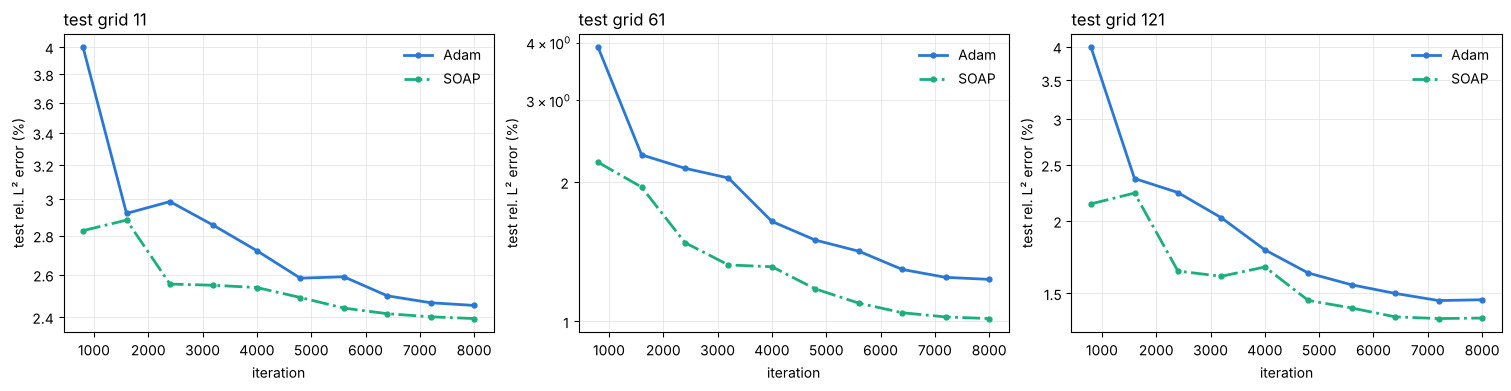

In [7]:
fig = an.plot_phase1("darcy", R, x="it"); plt.show()

## Fine-tuning with the $H^{-1}$ loss
(a) From the $H^{-1}$-trained Adam operator. (b) From the original $L^2$-trained Adam operator, the same start as notebook 02.

In [8]:
an.ft_table("darcy", R, base="adam_s0")

,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.009,5,1000,0.377,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",57
SOAP,0.009,5,1000,0.377,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",106


In [9]:
an.ft_table("darcy", R, base="l2adam_s0")

,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.003,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",56
Muon,0.009,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",57
SOAP,0.009,5,1000,2.535,0.119,"[0.106, 0.022, 0.256, 0.022, 0.187]",104


## Observations

- **The norm matters far more than the optimizer.** Over 5 seeds, on the 61² grid Adam goes from 8.91% ± 0.90 ($L^2$ loss) to **1.23% ± 0.03** ($H^{-1}$ loss), about 7×; SOAP goes from 5.00% ± 0.60 to **1.01% ± 0.01**, 5×. Swapping Adam for SOAP gains 1.8× with the $L^2$ loss and 1.2× with $H^{-1}$.
- **The $H^{-1}$ runs are also far more reproducible:** the seed-to-seed spread drops from ±0.6–0.9 points to ±0.01–0.03.
- **This matches or beats the paper's PINO** (1.56% on 61², with a network twice as wide).
- **The data-grid error barely moves** (2.6% → 2.4%): it is set by the data loss, which is unchanged.
- **Both optimizers chose lr 9e-3**, so the comparison has no learning-rate confound.
- **Fine-tuning ends at the same 0.12% floor for every start, loss and optimizer.** The flux-conservative system is square, so the $L^2$ and $H^{-1}$ losses share the exact discrete solution as minimizer: the norm changes how fast you get there, not where you land. The $H^{-1}$-trained operator simply starts much closer (0.38% against 2.54%).